# Final analyses: everything left for the paper

Reads the saved results of Experiment 6 (`results/realsim/`) and of the real-genome analyses (`results/multitool/`,
`results/Part2/`). Nothing is re-simulated except the Slope-SpaM step, and nothing existing is changed.
Everything is written to **`results/final/`**. Runtime: **about 20–25 minutes** on a Colab CPU runtime.

| Part | What | Time |
|---|---|---|
| A | The proposal's **two-rate-class estimator** (Table 1), with free *s* and with window *s*, plus a model choice by fit quality (AICc), on all 1,260 Experiment 6 pairs, from the saved k-mer counts | ~6 min |
| B | **Slope-SpaM** (published baseline from the proposal) on replicates 0–2 (378 pairs; each pair is rebuilt exactly from its seed and checked) | ~10 min |
| C | Final Experiment 6 tables: every estimator vs the **true** ANI, noise level, 95% misclassification, paired bootstrap | seconds |
| Fig 1 | Experiment 6: every method in every setting | seconds |
| D | Real genomes (100 pairs): **aligner ranking** and where our estimators land | ~1 min |
| Fig 2 | Real genomes: each method relative to dnadiff | seconds |
| E | `key_numbers.txt`: the numbers the paper needs (H1, H2, H3, weak spots, real genomes) | seconds |

Not repeated here, on purpose: 10 replicates of Experiments 1–4 (Experiment 6 covers the same settings on real
chromosomes with 10 replicates), and more real pairs near 95% (a stated limitation).

**How to run:** put this notebook in `CMPS355_ANI_Project`, use a **CPU** runtime, Runtime → Run all.
Re-running is quick: Parts A and B reuse their saved results.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
PROJECT = "/content/drive/MyDrive/CMPS355_ANI_Project"
TOOLS   = "/content/tools"
LIB     = "/content/final_lib"

import os, sys, glob, time, subprocess
RESULTS = f"{PROJECT}/results"; RS = f"{RESULTS}/realsim"; OUTF = f"{RESULTS}/final"
for d in [OUTF, TOOLS, LIB]: os.makedirs(d, exist_ok=True)
open(f"{LIB}/__init__.py", "w").close(); sys.path.insert(0, os.path.dirname(LIB))
n_raw = sum(len(open(f).readlines()) - 1 for f in glob.glob(f"{RS}/raw_w*.csv") if "_quick" not in f)
n_curves = len(glob.glob(f"{RS}/curves/job_*.npz"))
print(f"Experiment 6 rows: {n_raw} | saved k-mer count files: {n_curves}")
assert n_curves > 0 and os.path.exists(f"{RS}/realsim.py"), "results/realsim not found: run Experiment 6 first"
assert os.path.exists(f"{RESULTS}/multitool/real_all_tools.csv"), "results/multitool not found"
print("Writing to:", OUTF)

Experiment 6 rows: 1260 | saved k-mer count files: 1260
Writing to: /content/drive/MyDrive/CMPS355_ANI_Project/results/final


In [3]:
# ---------------- Slope-SpaM: build from source (about 2 minutes, once per Colab session) ----------------
SLOPE_SPAM = f"{TOOLS}/Slope-SpaM/build/slope-spam"
if not os.path.exists(SLOPE_SPAM):
    subprocess.run(f"cd {TOOLS} && rm -rf Slope-SpaM && git clone -q --recursive https://github.com/burkhard-morgenstern/Slope-SpaM.git "
                   "&& cd Slope-SpaM && mkdir -p build && cd build && cmake -DCMAKE_BUILD_TYPE=Release .. > /dev/null "
                   "&& make -j2 slope-spam > /dev/null", shell=True, check=True)
commit = subprocess.run(["git", "-C", f"{TOOLS}/Slope-SpaM", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Slope-SpaM ready:", os.path.exists(SLOPE_SPAM), "| commit", commit)

Slope-SpaM ready: True | commit 3fbf226


### Shared code (estimators, Slope-SpaM runner, real-genome helpers)

In [4]:
%%writefile {LIB}/estimators.py
# ---------------- estimators shared by all parts (gamma copied unchanged from the project) ----------------
import numpy as np
from scipy.optimize import curve_fit, least_squares

KS = np.arange(15, 32, 2)

def gamma_model(k, s, d, alpha): return np.log(s) - alpha * np.log1p(k * d / alpha)

def est_gamma(C, ks=KS):
    """original multi-k gamma (s free) -> ANI, s, alpha"""
    y = np.log(C); slope, inter = np.polyfit(ks, y, 1); s0, d0 = np.exp(inter), max(-slope, 1e-4); best = None
    for a0 in [0.3, 1, 5, 50]:
        try:
            p, _ = curve_fit(gamma_model, ks, y, p0=[min(s0, 0.99), d0, a0], bounds=([1e-6, 1e-6, 0.01], [1, 3, 1000]), maxfev=20000)
            err = np.sum((gamma_model(ks, *p) - y) ** 2)
            if best is None or err < best[1]: best = (p, err)
        except RuntimeError: pass
    s, d, a = best[0]; return (1 + d / a) ** (-a), s, a

def est_gamma_s_fixed(C, s_fixed, ks=KS):
    """C: window s, then gamma fit of d and alpha -> ANI"""
    y = np.log(np.maximum(C, 1e-12)); slope, _ = np.polyfit(ks, y, 1); d0 = max(-slope, 1e-4); best = None
    f = lambda k, d, a: gamma_model(k, s_fixed, d, a)
    for a0 in [0.3, 1, 5, 50]:
        try:
            q, _ = curve_fit(f, ks, y, p0=[d0, a0], bounds=([1e-6, 0.01], [3, 1000]), maxfev=20000)
            sse = np.sum((f(ks, *q) - y) ** 2)
            if best is None or sse < best[1]: best = (q, sse)
        except (RuntimeError, ValueError): pass
    d, a = best[0]; return (1 + d / a) ** (-a)

# ---------------- two-rate-class model (proposal, Table 1) ----------------
# Shared regions come in two classes: a fraction f with identity q1 and 1-f with identity q2 <= q1.
#   C(k) = s * [ f q1^k + (1-f) q2^k ],   ANI = f q1 + (1-f) q2
# Settings fixed in advance (not tuned on results): identities limited to [0.60, 1] (below ~60% identity
# a region is no longer recognisably homologous), multi-start least squares on log C(k), k = 15..31.
Q_MIN = 0.60

def _two_class_log(k, s, f, q1, q2):
    return np.log(s) + np.log(f * q1 ** k + (1 - f) * q2 ** k + 1e-300)

def est_two_class(C, s_fixed=None, ks=KS):
    """-> ANI, s, f, q1, q2.  s free, or fixed (e.g. to the window estimate)"""
    ks = np.asarray(ks, float); y = np.log(np.maximum(C, 1e-12)); best = None
    slope, inter = np.polyfit(ks, y, 1); q0 = float(np.clip(np.exp(slope), Q_MIN + 0.01, 0.999))
    for f0 in (0.3, 0.6, 0.9):
        for gap in (0.02, 0.08, 0.2):
            q1_0 = min(0.999, q0 + gap / 2); q2_0 = max(Q_MIN + 0.005, q0 - gap / 2)
            if s_fixed is None:
                x0 = [min(np.exp(inter), 0.99) if inter < 0 else 0.9, f0, q1_0, q2_0]
                lo, hi = [1e-6, 0, Q_MIN, Q_MIN], [1, 1, 1, 1]
                fun = lambda p: _two_class_log(ks, p[0], p[1], p[2], min(p[3], p[2])) - y
            else:
                x0 = [f0, q1_0, q2_0]; lo, hi = [0, Q_MIN, Q_MIN], [1, 1, 1]
                fun = lambda p: _two_class_log(ks, s_fixed, p[0], p[1], min(p[2], p[1])) - y
            try:
                r = least_squares(fun, x0, bounds=(lo, hi), max_nfev=5000)
                if best is None or r.cost < best.cost: best = r
            except ValueError: pass
    p = best.x
    s, f, q1, q2 = (p[0], p[1], p[2], min(p[3], p[2])) if s_fixed is None else (s_fixed, p[0], p[1], min(p[2], p[1]))
    return f * q1 + (1 - f) * q2, s, f, q1, q2

# ---------------- choosing between the two models per pair (AICc; rule fixed in advance) ----------------
def _sse_gamma(C, s, d, a, ks=KS): return float(np.sum((gamma_model(np.asarray(ks, float), s, d, a) - np.log(C)) ** 2))

def gamma_fit(C, s_fixed=None, ks=KS):
    """-> ANI, s, d, alpha, SSE   (identical results to est_gamma / est_gamma_s_fixed)"""
    y = np.log(np.maximum(C, 1e-12)); slope, inter = np.polyfit(ks, y, 1); s0, d0 = np.exp(inter), max(-slope, 1e-4); best = None
    for a0 in [0.3, 1, 5, 50]:
        try:
            if s_fixed is None:
                p, _ = curve_fit(gamma_model, ks, y, p0=[min(s0, 0.99), d0, a0], bounds=([1e-6, 1e-6, 0.01], [1, 3, 1000]), maxfev=20000)
            else:
                f = lambda k, d, a: gamma_model(k, s_fixed, d, a)
                q, _ = curve_fit(f, ks, y, p0=[d0, a0], bounds=([1e-6, 0.01], [3, 1000]), maxfev=20000); p = np.array([s_fixed, *q])
            sse = np.sum((gamma_model(ks, *p) - y) ** 2)
            if best is None or sse < best[1]: best = (p, sse)
        except (RuntimeError, ValueError): pass
    s, d, a = best[0]; return (1 + d / a) ** (-a), s, d, a, float(best[1])

def two_class_fit(C, s_fixed=None, ks=KS):
    ani, s, f, q1, q2 = est_two_class(C, s_fixed, ks)
    sse = float(np.sum((_two_class_log(np.asarray(ks, float), s, f, q1, q2) - np.log(np.maximum(C, 1e-12))) ** 2))
    return ani, s, f, q1, q2, sse

def aicc(sse, n, p): return n * np.log(max(sse, 1e-300) / n) + 2 * p + 2 * p * (p + 1) / (n - p - 1)

def select_model(C, s_fixed=None, ks=KS):
    """fit both models; return the ANI of the one with the lower AICc (+ both ANIs and the choice)"""
    g = gamma_fit(C, s_fixed, ks); t = two_class_fit(C, s_fixed, ks); n = len(ks)
    pg, pt = (3, 4) if s_fixed is None else (2, 3)
    use_two = aicc(t[-1], n, pt) < aicc(g[-1], n, pg)
    return (t[0] if use_two else g[0]), g[0], t[0], bool(use_two)


Writing /content/final_lib/estimators.py


In [5]:
%%writefile {LIB}/slopespam_part.py
# ---------------- Slope-SpaM on Experiment 6 (replicates 0-2, the same pairs dnadiff was run on) ----------------
# The genome pairs were not stored, but each one is rebuilt exactly from its seed with the saved realsim.py,
# and the rebuilt pair's true ANI is checked against the saved value before Slope-SpaM is run.
import os, sys, time, subprocess, numpy as np, pandas as pd
from multiprocessing import get_context

def load_simulator(realsim_path, project):
    """execute the saved realsim.py definitions (not its main loop or tool imports) and return them as a namespace"""
    src = open(realsim_path).read()
    src = src.replace("import pyskani, sourmash", "")                # tools are not needed to rebuild the pairs
    src = src.replace('assert MASH_BIN and shutil.which("dnadiff"), "Mash or dnadiff not found"', "")
    src = src.split('if __name__ == "__main__":')[0]
    ns = {"__name__": "realsim_defs"}
    argv, sys.argv = sys.argv, ["realsim.py", project, "/nonexistent", "0", "1"]
    try: exec(compile(src, realsim_path, "exec"), ns)
    finally: sys.argv = argv
    return ns

def jc_to_ani(d): return 1 - 0.75 * (1 - np.exp(-4 * d / 3))       # Jukes-Cantor distance -> identity

_SIM = {}                                                           # filled in the main process, inherited by workers (fork)

def _one(task):
    j, expected_true = task
    try:
        ns = _SIM["ns"]
        jobs = [(g, s, t, r) for r in range(ns["REPS"]) for g in ns["GENOMES"] for s in ns["SETTINGS"] for t in ns["TARGETS"]]
        gname, sname, target, rep = jobs[j]
        if gname not in _SIM["A"]: _SIM["A"] = {gname: ns["chromosome"](ns["GENOMES"][gname])}
        A = _SIM["A"][gname]; fn, gd = ns["SETTINGS"][sname]
        B, true_ani, _, _ = ns["make_pair"](np.random.default_rng(10_000 + j), A, 1 - target, fn, gd, _SIM["foreign"])
        if abs(true_ani - expected_true) > 1e-12:
            return {"job": j, "error": f"not reproduced (true ANI {true_ani:.6f} vs saved {expected_true:.6f})"}
        fa, out = f"{_SIM['tmp']}/pair_{os.getpid()}.fasta", f"{_SIM['tmp']}/pair_{os.getpid()}.dmat"
        with open(fa, "wb") as f: f.write(b">A\n" + ns["DEC"][A].tobytes() + b"\n>B\n" + ns["DEC"][B].tobytes() + b"\n")
        subprocess.run([_SIM["bin"], "-t", "1", "-o", out, fa], capture_output=True, check=True)
        d = float(open(out).read().split("\n")[1].split()[2])        # row "A  0  d"
        return {"job": j, "slope_spam": jc_to_ani(d), "slope_spam_jc": d, "reproduced": True}
    except Exception as e:                                          # report, never crash the pool
        return {"job": j, "error": f"{type(e).__name__}: {e}"}

def run_slope_spam(raw, realsim_path, project, binary, out_csv, tmpdir="/tmp/sspam_work", n_proc=2, reps=(0, 1, 2)):
    """returns a table of Slope-SpaM estimates, or None (with a message) if the pairs cannot be rebuilt here"""
    os.makedirs(tmpdir, exist_ok=True)
    done = set(pd.read_csv(out_csv).job) if os.path.exists(out_csv) else set()
    todo = [(int(r.job), float(r.true)) for r in raw[raw.rep.isin(reps)].itertuples() if r.job not in done]
    print(f"Slope-SpaM: {len(todo)} pairs to run ({len(done)} already done)", flush=True)
    if todo:
        _SIM.update(ns=load_simulator(realsim_path, project), bin=binary, tmp=tmpdir, A={})
        _SIM["foreign"] = _SIM["ns"]["chromosome"](_SIM["ns"]["FOREIGN"])
        first = _one(todo[0])                                       # fail fast, in the main process
        if "error" in first:
            print("STOPPED before running Slope-SpaM on all pairs:", first["error"])
            print("Slope-SpaM is skipped; every other part of this notebook still runs.")
            return None
        pd.DataFrame([first]).to_csv(out_csv, mode="a", header=not os.path.exists(out_csv), index=False)
        t0, errors = time.time(), []
        with get_context("fork").Pool(n_proc) as pool:
            for n, row in enumerate(pool.imap_unordered(_one, todo[1:]), 2):
                if "error" in row: errors.append(row); continue
                pd.DataFrame([row]).to_csv(out_csv, mode="a", header=not os.path.exists(out_csv), index=False)
                if n % 25 == 0 or n == len(todo):
                    print(f"  {n}/{len(todo)} done, {(time.time() - t0) / 60:.1f} min", flush=True)
        if errors:
            print(f"{len(errors)} pairs failed, e.g. job {errors[0]['job']}: {errors[0]['error']} (re-run this cell to retry them)")
    return pd.read_csv(out_csv) if os.path.exists(out_csv) else None


Writing /content/final_lib/slopespam_part.py


In [6]:
%%writefile {LIB}/real_part.py
# ---------------- real genomes: the new estimators on the 100 real pairs, and the aligner ranking ----------------
import numpy as np, pandas as pd

def real_curve(F, ks=np.arange(15, 32, 2)):
    """same k-mer curve and window-s rule as Model-G (canonical k-mers, composition-matched background)"""
    allk = F["ks"]; m = np.isin(allk, ks)
    nA, nB, sh, shr = [F[x].astype(float) for x in ["nA", "nB", "shared", "shared_rev"]]
    C = (np.maximum(sh - nA * nB / (4.0 ** allk / 2), 1) / nA)[m]
    i = np.where(allk == 21)[0][0]; bg = shr / nA
    V, H = F["win_valid"][i], F["win_shared"][i]; ok = V >= 500
    sw = ((H >= 1 + V * bg[i]) & ok).sum() / ok.sum()
    return C, min(sw, 1)

def boot_ci(x, n=5000, seed=0):
    r = np.random.default_rng(seed); idx = r.integers(0, len(x), (n, len(x))); return np.percentile(x[idx].mean(1), [2.5, 97.5])


Writing /content/final_lib/real_part.py


## Part A: two-rate-class estimator and model choice (Experiment 6)

In [7]:
# ---------------- Part A: the remaining estimators from the proposal's Table 1, on all 1,260 Experiment 6 pairs ----------------
import glob, numpy as np, pandas as pd
from multiprocessing import get_context
from final_lib.estimators import KS, select_model

raw = pd.concat([pd.read_csv(f) for f in glob.glob(f"{RS}/raw_w*.csv") if "_quick" not in f]).drop_duplicates("job").sort_values("job").reset_index(drop=True)
print("Experiment 6 pairs:", len(raw))

def new_estimates(j):
    F = np.load(f"{RS}/curves/job_{j}.npz"); ks = F["ks"]; m = np.isin(ks, KS)
    C = np.maximum(F["shared"][m] - F["nA"][m] * F["nB"][m] / 4.0 ** ks[m], 1) / F["nA"][m]   # same correction as Exp 6
    sw = min((F["win21"] >= 1).mean(), 1)
    sel, g, t, use = select_model(C); selw, gw, tw, usew = select_model(C, sw)
    return {"job": j, "original (recomputed)": g, "C (recomputed)": gw, "two-class": t, "two-class + window s": tw,
            "AICc choice": sel, "AICc choice + window s": selw, "picked two-class": use, "picked two-class (window s)": usew}

NEW_FILE = f"{OUTF}/exp6_new_estimators.csv"
if os.path.exists(NEW_FILE) and len(pd.read_csv(NEW_FILE)) == len(raw):
    new = pd.read_csv(NEW_FILE); print("Loaded", NEW_FILE)
else:
    t0 = time.time()
    with get_context("fork").Pool(os.cpu_count()) as pool: new = pd.DataFrame(pool.map(new_estimates, raw.job.tolist(), chunksize=8))
    new.to_csv(NEW_FILE, index=False); print(f"Computed in {(time.time() - t0) / 60:.1f} min -> {NEW_FILE}")
ex6 = raw.merge(new, on="job")
# check: recomputing the saved estimators from the saved counts gives exactly the saved values
assert np.allclose(ex6["original (recomputed)"], ex6["original"], atol=1e-9) and np.allclose(ex6["C (recomputed)"], ex6["C: window s"], atol=1e-9)
print("Check passed: the saved k-mer counts reproduce the saved estimates exactly.")

Experiment 6 pairs: 1260
Loaded /content/drive/MyDrive/CMPS355_ANI_Project/results/final/exp6_new_estimators.csv
Check passed: the saved k-mer counts reproduce the saved estimates exactly.


## Part B: Slope-SpaM baseline (Experiment 6, replicates 0–2)

In [8]:
# ---------------- Part B: Slope-SpaM (published baseline from the proposal) on replicates 0-2 ----------------
from final_lib.slopespam_part import run_slope_spam
ss = run_slope_spam(raw, f"{RS}/realsim.py", PROJECT, SLOPE_SPAM, f"{OUTF}/exp6_slope_spam.csv",
                    n_proc=os.cpu_count(), reps=(0, 1, 2))
ex6 = ex6.drop(columns=[c for c in ["Slope-SpaM"] if c in ex6])
if ss is not None and "slope_spam" in ss:
    ex6 = ex6.merge(ss[["job", "slope_spam"]].dropna(), on="job", how="left").rename(columns={"slope_spam": "Slope-SpaM"})
else:
    ex6["Slope-SpaM"] = np.nan
print("Slope-SpaM estimates:", int(ex6["Slope-SpaM"].notna().sum()), "pairs (each rebuilt exactly from its seed and checked)")

Slope-SpaM: 378 pairs to run (0 already done)
  25/378 done, 1.5 min
  50/378 done, 3.1 min
  75/378 done, 4.8 min
  100/378 done, 5.8 min
  125/378 done, 6.4 min
  150/378 done, 8.0 min
  175/378 done, 9.7 min
  200/378 done, 11.4 min
  225/378 done, 12.5 min
  250/378 done, 13.2 min
  275/378 done, 14.6 min
  300/378 done, 16.2 min
  325/378 done, 18.0 min
  350/378 done, 19.0 min
  375/378 done, 19.7 min
  378/378 done, 19.8 min
Slope-SpaM estimates: 378 pairs (each rebuilt exactly from its seed and checked)


## Part C: Experiment 6, final tables

In [9]:
# ---------------- Part C: Experiment 6, final tables (everything scored against the TRUE ANI) ----------------
pd.set_option("display.width", 250)
TOOLS6 = ["Mash (tool)", "sourmash", "skani", "Slope-SpaM", "dnadiff"]
TABLE1 = ["Mash formula", "uniform (control)", "two-class", "original"]           # the proposal's Table 1, in order
EXTRA  = ["C: window s", "two-class + window s", "G: window s + aligned-only", "AICc choice"]
EST6 = [e for e in TOOLS6 + TABLE1 + EXTRA if ex6[e].notna().any()]
ORDER = [s for s in ["Uniform", "Gamma a=2", "Gamma a=0.5", "Two-class", "Wave", "Gamma a=2 + 20% foreign genes"] if s in set(ex6.setting)]
c6 = ex6.dropna(subset=["skani", "sourmash"]).copy()                             # skani gives no estimate below ~82%
for e in EST6: c6[f"err::{e}"] = (c6[e] - c6.true) * 100
unev = c6[c6.setting != "Uniform"]
print(f"Pairs scored: {len(c6)} of {len(ex6)} (dropped where skani/sourmash gave no estimate). "
      "dnadiff and Slope-SpaM: replicates 0-2 only.")

def tab(stat):
    f = (lambda x: x.mean()) if stat == "mean" else (lambda x: x.abs().mean())
    t = pd.DataFrame({e: c6.dropna(subset=[e]).groupby("setting")[f"err::{e}"].apply(f).reindex(ORDER) for e in EST6})
    t.loc["ALL uneven"] = [f(unev.dropna(subset=[e])[f"err::{e}"]) for e in EST6]
    return t.round(2)
mean6, abs6 = tab("mean"), tab("abs")
print("\n=== Table 1 estimators + tools: mean |error| vs true ANI (ANI points) ===")
print(abs6.T.to_string())
print("\n=== Mean error (+ = overestimates) ===")
print(mean6.T.to_string())

rep_sd = (c6.groupby(["setting", "rep"])[[f"err::{e}" for e in EST6]].apply(lambda d: d.abs().mean())
          .groupby("setting").std().rename(columns=lambda x: x[5:]).reindex(ORDER).round(2))
print("\n=== Noise level: SD of mean |error| across replicates ===")
print(rep_sd.T.to_string())

clear = c6[(c6.true - 0.95).abs() > 0.005]
def wrong(d, e):
    d = d.dropna(subset=[e]); return int((((d.true < .95) & (d[e] >= .95)) | ((d.true >= .95) & (d[e] < .95))).sum())
mis6 = pd.DataFrame({e: [wrong(clear[clear.setting == s], e) for s in ORDER] + [wrong(clear, e), len(clear.dropna(subset=[e]))]
                     for e in EST6}, index=ORDER + ["TOTAL", "pairs counted"])
print("\n=== Wrong side of the 95% species line (pairs within 0.5 pt of 95% excluded) ===")
print(mis6.T.to_string())

rs = np.random.default_rng(0); rows = []
for ours in ["original", "C: window s", "two-class"]:
    for e in [x for x in EST6 if x != ours]:
        d = unev.dropna(subset=[e]); a, b = d[f"err::{ours}"].abs().values, d[f"err::{e}"].abs().values
        idx = rs.integers(0, len(a), (5000, len(a))); bt = a[idx].mean(1) - b[idx].mean(1)
        rows.append({"ours": ours, "vs": e, "n": len(d), "difference in mean |error|": round(a.mean() - b.mean(), 2),
                     "95% CI": f"[{np.percentile(bt, 2.5):+.2f}, {np.percentile(bt, 97.5):+.2f}]"})
paired6 = pd.DataFrame(rows)
print("\n=== Paired comparisons, uneven settings (negative = ours better) ===")
print(paired6[paired6.vs.isin(TOOLS6 + ["uniform (control)", "Mash formula"])].to_string(index=False))

print("\n=== Model choice by fit quality (AICc): how often the two-class model is picked ===")
print(c6.groupby("setting")[["picked two-class", "picked two-class (window s)"]].mean().reindex(ORDER).round(2).to_string())

print("\n=== Recovered unevenness (median fitted alpha) ===")
print(c6.groupby("setting")[["alpha_orig", "alpha_C", "s_orig", "s_window", "true_s"]].median().reindex(ORDER).round(2).to_string())

for n, t in [("exp6_mean_abs_error", abs6), ("exp6_mean_error", mean6), ("exp6_replicate_sd", rep_sd), ("exp6_misclassified", mis6)]:
    t.to_csv(f"{OUTF}/{n}.csv")
paired6.to_csv(f"{OUTF}/exp6_paired_bootstrap.csv", index=False)
ex6.to_csv(f"{OUTF}/exp6_all_estimates.csv", index=False)

Pairs scored: 1200 of 1260 (dropped where skani/sourmash gave no estimate). dnadiff and Slope-SpaM: replicates 0-2 only.

=== Table 1 estimators + tools: mean |error| vs true ANI (ANI points) ===
setting                     Uniform  Gamma a=2  Gamma a=0.5  Two-class  Wave  Gamma a=2 + 20% foreign genes  ALL uneven
Mash (tool)                    1.02       3.01         5.62       3.30  1.29                           2.37        3.12
sourmash                       0.60       3.34         5.74       3.62  1.79                           2.67        3.43
skani                          1.28       2.07         4.77       2.73  2.43                           2.03        2.81
Slope-SpaM                     2.16       4.63         6.99       3.65  2.52                           4.55        4.47
dnadiff                        1.76       2.38         4.30       3.68  2.25                           2.43        3.01
Mash formula                   0.97       3.05         5.66       3.35  1.29        

Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/final/fig1_exp6_errors.png


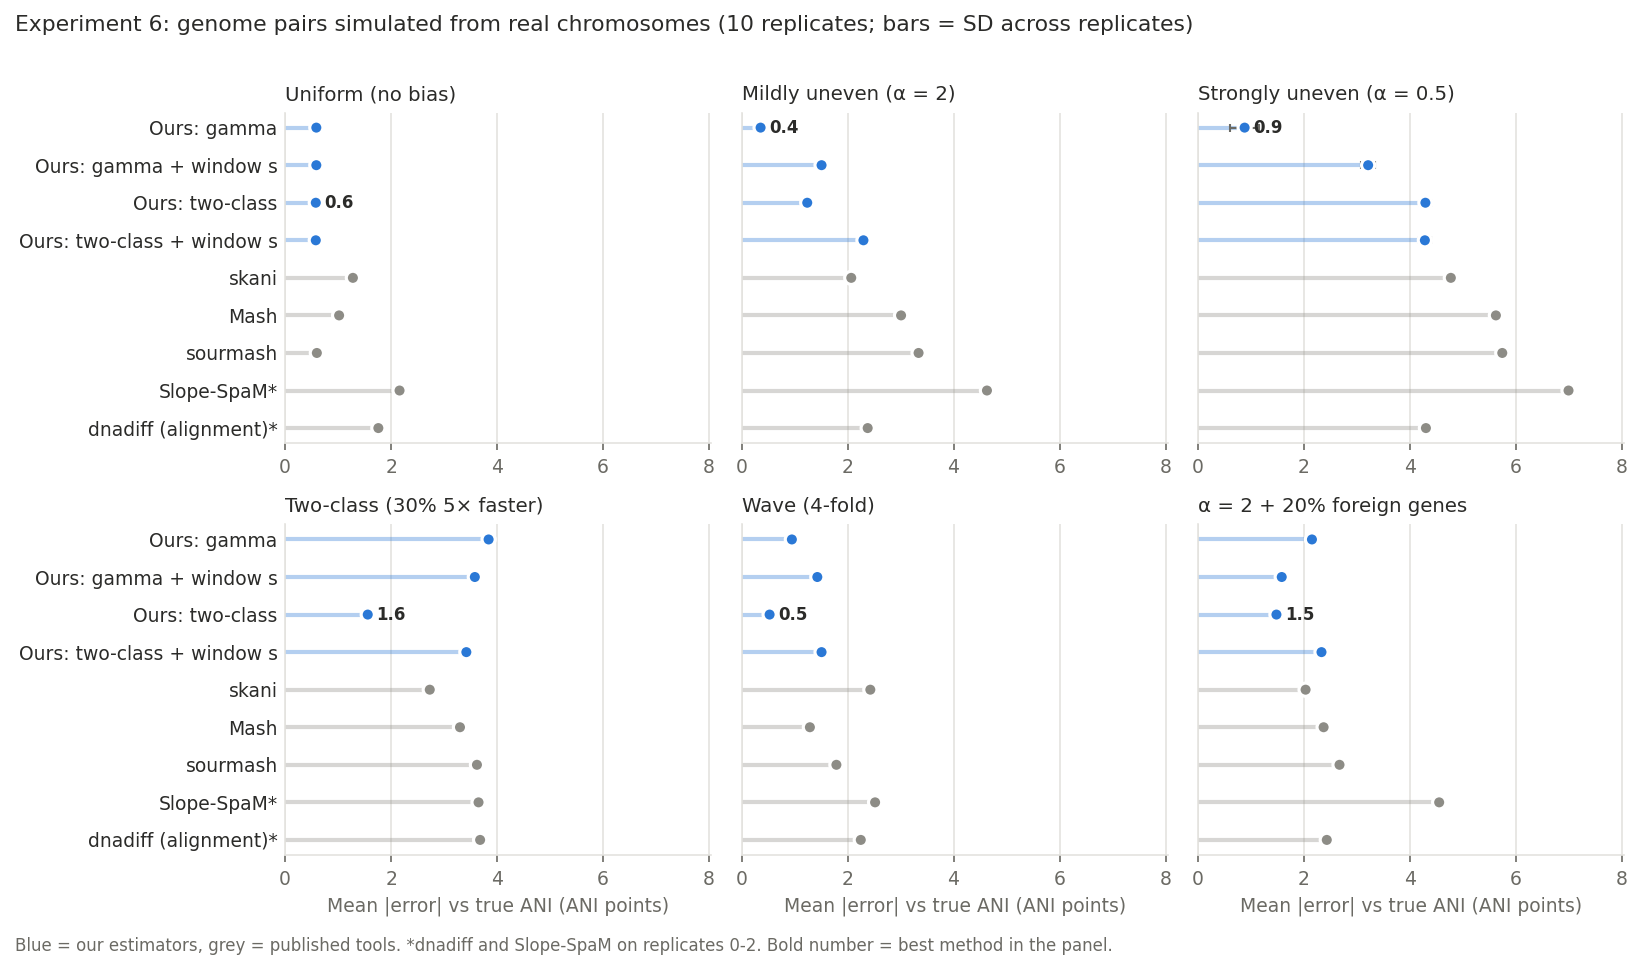

In [10]:
# ---------------- Figure 1: Experiment 6, mean |error| of every method in every setting ----------------
import matplotlib.pyplot as plt
OURS_C, TOOL_C, INK, INK2, GRID = "#2a78d6", "#8d8c86", "#2b2b29", "#6b6a64", "#e4e3df"
SHOW = [e for e in ["original", "C: window s", "two-class", "two-class + window s",
                    "skani", "Mash (tool)", "sourmash", "Slope-SpaM", "dnadiff"] if e in EST6]
NAMES = {"original": "Ours: gamma", "C: window s": "Ours: gamma + window s", "two-class": "Ours: two-class",
         "two-class + window s": "Ours: two-class + window s", "skani": "skani", "Mash (tool)": "Mash", "sourmash": "sourmash",
         "Slope-SpaM": "Slope-SpaM*", "dnadiff": "dnadiff (alignment)*"}
TITLES = {"Uniform": "Uniform (no bias)", "Gamma a=2": "Mildly uneven (α = 2)", "Gamma a=0.5": "Strongly uneven (α = 0.5)",
          "Two-class": "Two-class (30% 5× faster)", "Wave": "Wave (4-fold)", "Gamma a=2 + 20% foreign genes": "α = 2 + 20% foreign genes"}
plt.rcParams.update({"font.size": 9, "axes.edgecolor": GRID, "xtick.color": INK2, "ytick.color": INK})
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4), dpi=150, sharey=True)
xmax = np.nanmax(abs6.loc[ORDER, SHOW].values) * 1.15
y = np.arange(len(SHOW))[::-1]
for ax, s in zip(axes.flat, ORDER):
    v = abs6.loc[s, SHOW].values.astype(float); sd = np.nan_to_num(rep_sd.loc[s, SHOW].values.astype(float))
    col = [OURS_C if e in ("original", "C: window s", "two-class", "two-class + window s") else TOOL_C for e in SHOW]
    ax.hlines(y, 0, v, color=col, linewidth=2, alpha=0.35)
    ax.errorbar(v, y, xerr=sd, fmt="none", ecolor=INK2, elinewidth=1, capsize=2, zorder=3)
    ax.scatter(v, y, s=40, c=col, edgecolor="white", linewidth=1.5, zorder=4)
    best = np.nanargmin(v); ax.text(v[best] + xmax * 0.02, y[best], f"{v[best]:.1f}", va="center", fontsize=8, color=INK, fontweight="bold")
    ax.set_title(TITLES[s], fontsize=9.5, color=INK, loc="left"); ax.set_xlim(0, xmax)
    ax.grid(axis="x", color=GRID); ax.spines[["top", "right"]].set_visible(False); ax.tick_params(axis="y", length=0)
for ax in axes[:, 0]: ax.set_yticks(y); ax.set_yticklabels([NAMES[e] for e in SHOW])
for ax in axes[1, :]: ax.set_xlabel("Mean |error| vs true ANI (ANI points)", color=INK2)
fig.suptitle("Experiment 6: genome pairs simulated from real chromosomes (10 replicates; bars = SD across replicates)",
             x=0.01, ha="left", fontsize=10.5, color=INK)
fig.text(0.01, 0.005, "Blue = our estimators, grey = published tools. *dnadiff and Slope-SpaM on replicates 0-2. "
         "Bold number = best method in the panel.", fontsize=8, color=INK2)
plt.tight_layout(rect=(0, 0.02, 1, 0.97)); plt.savefig(f"{OUTF}/fig1_exp6_errors.png", bbox_inches="tight", facecolor="white")
print("Saved:", f"{OUTF}/fig1_exp6_errors.png"); plt.show()

## Part D: real genomes, aligner ranking

In [11]:
# ---------------- Part D: real genomes (Experiment 5 / Model-G pairs): where does each method land? ----------------
from final_lib.real_part import real_curve, boot_ci
from final_lib.estimators import est_two_class, est_gamma, est_gamma_s_fixed
R = pd.read_csv(f"{RESULTS}/multitool/real_all_tools.csv")
extra = []
for p in R.itertuples():
    f = (f"{RESULTS}/multitool/features/{p.acc_a}__{p.acc_b}.npz" if p.set == "held-out"
         else f"{RESULTS}/Part2/features/{p.acc_a}__{p.acc_b}.npz")
    C, sw = real_curve(dict(np.load(f)))
    extra.append({"two-class": est_two_class(C)[0], "two-class + window s": est_two_class(C, sw)[0],
                  "_orig": est_gamma(C)[0], "_C": est_gamma_s_fixed(C, sw)})
R = pd.concat([R, pd.DataFrame(extra)], axis=1)
assert np.allclose(R._orig, R.original, atol=1e-9) and np.allclose(R._C, R["C: window s"], atol=1e-9)
R = R.drop(columns=["_orig", "_C"]).dropna(subset=["ANIb", "FastANI", "nucmer -l15"])
ALIGN = ["dnadiff", "nucmer -l15", "FastANI", "ANIb"]                 # least -> most sensitive aligner
KMER = ["Mash (tool)", "skani"]
OURS_R = ["original", "C: window s", "two-class", "two-class + window s", "G: window s + aligned-only"]
METH = ALIGN + KMER + OURS_R
rows = []
for S in ["development", "held-out"]:
    d = R[R.set == S]
    for m in METH:
        diff = (d[m] - d.dnadiff).values * 100; lo, hi = boot_ci(diff)
        rows.append({"pairs": S, "method": m, "n": len(d), "mean ANI (%)": round(d[m].mean() * 100, 2),
                     "minus dnadiff": round(diff.mean(), 2), "CI low": round(lo, 2), "CI high": round(hi, 2)})
rank = pd.DataFrame(rows); rank.to_csv(f"{OUTF}/real_aligner_ranking.csv", index=False)
print("=== Real genomes: mean ANI and difference from dnadiff [95% CI] ===")
print(rank.to_string(index=False))
d = R.assign(bin=pd.cut(R.dnadiff, [0.80, 0.90, 0.95, 0.99]))
by_bin = (d.groupby("bin", observed=True)[METH].mean() * 100).round(2).T
print("\n=== Mean ANI (%) by divergence (dnadiff bins), all 100 pairs ==="); print(by_bin.to_string())
by_bin.to_csv(f"{OUTF}/real_by_divergence.csv")

=== Real genomes: mean ANI and difference from dnadiff [95% CI] ===
      pairs                     method  n  mean ANI (%)  minus dnadiff  CI low  CI high
development                    dnadiff 73         92.88           0.00    0.00     0.00
development                nucmer -l15 73         92.61          -0.27   -0.34    -0.20
development                    FastANI 73         92.34          -0.53   -0.67    -0.40
development                       ANIb 73         92.01          -0.87   -1.08    -0.66
development                Mash (tool) 73         93.17           0.30    0.22     0.38
development                      skani 73         92.38          -0.50   -0.64    -0.36
development                   original 73         90.77          -2.11   -2.66    -1.57
development                C: window s 73         92.22          -0.66   -0.86    -0.46
development                  two-class 73         91.63          -1.25   -1.54    -0.96
development       two-class + window s 73         92

Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/final/fig2_real_aligner_ranking.png


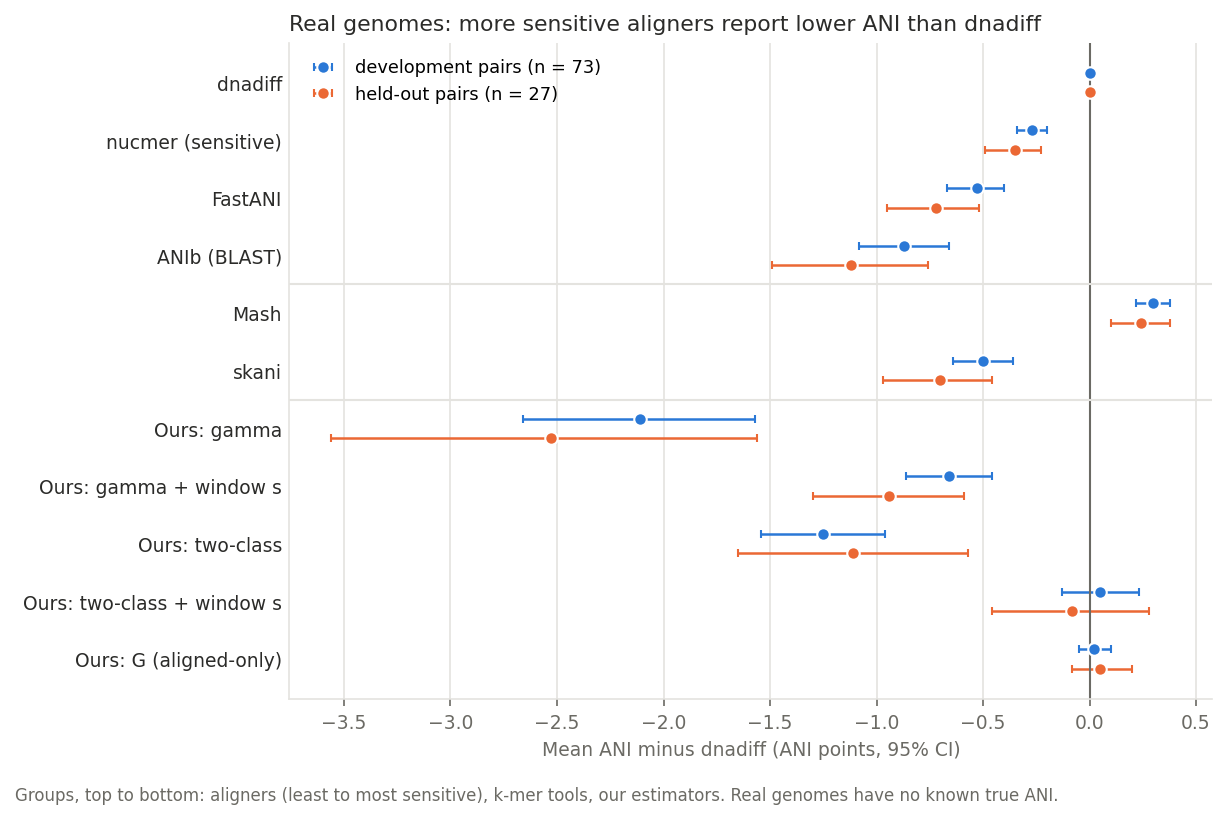

In [12]:
# ---------------- Figure 2: real genomes, each method's ANI relative to dnadiff ----------------
NAMES_R = {"dnadiff": "dnadiff", "nucmer -l15": "nucmer (sensitive)", "FastANI": "FastANI", "ANIb": "ANIb (BLAST)",
           "Mash (tool)": "Mash", "skani": "skani", "original": "Ours: gamma", "C: window s": "Ours: gamma + window s",
           "two-class": "Ours: two-class", "two-class + window s": "Ours: two-class + window s",
           "G: window s + aligned-only": "Ours: G (aligned-only)"}
SETC = {"development": "#2a78d6", "held-out": "#eb6834"}
fig, ax = plt.subplots(figsize=(8.2, 5.4), dpi=150)
y = np.arange(len(METH))[::-1]
for i, (S, colr) in enumerate(SETC.items()):
    r = rank[rank.pairs == S].set_index("method").loc[METH]; off = (0.17 if i == 0 else -0.17)
    ax.errorbar(r["minus dnadiff"], y + off, xerr=[r["minus dnadiff"] - r["CI low"], r["CI high"] - r["minus dnadiff"]],
                fmt="o", color=colr, ecolor=colr, elinewidth=1.2, capsize=2, markersize=6, markeredgecolor="white",
                label=f"{S} pairs (n = {int(r.n.iloc[0])})")
ax.axvline(0, color=INK2, linewidth=1)
for yy in (len(METH) - len(ALIGN) - 0.5, len(OURS_R) - 0.5): ax.axhline(yy, color=GRID, linewidth=1)
ax.set_yticks(y); ax.set_yticklabels([NAMES_R[m] for m in METH], color=INK)
ax.set_xlabel("Mean ANI minus dnadiff (ANI points, 95% CI)", color=INK2)
ax.grid(axis="x", color=GRID); ax.spines[["top", "right"]].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_title("Real genomes: more sensitive aligners report lower ANI than dnadiff", loc="left", fontsize=10.5, color=INK)
fig.text(0.01, 0.005, "Groups, top to bottom: aligners (least to most sensitive), k-mer tools, our estimators. "
         "Real genomes have no known true ANI.", fontsize=8, color=INK2)
ax.legend(frameon=False, loc="upper left", fontsize=8.5)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig(f"{OUTF}/fig2_real_aligner_ranking.png", bbox_inches="tight", facecolor="white")
print("Saved:", f"{OUTF}/fig2_real_aligner_ranking.png"); plt.show()

## Part E: key numbers for the paper

In [13]:
# ---------------- Part E: the numbers the paper needs, in one place ----------------
g = lambda t, r, c: float(t.loc[r, c]) if (r in t.index and c in t.columns) else float("nan")   # nan if a method is missing
m = lambda c: mis6.loc["TOTAL", c] if c in mis6.columns else "n/a"
pick = c6.groupby("setting")["picked two-class"].mean()
lines = [
 "KEY NUMBERS (Experiment 6: 1,260 pairs from real chromosomes, 10 replicates; errors vs TRUE ANI, ANI points)",
 f"H1 bias exists: Mash overestimates by {g(mean6,'ALL uneven','Mash (tool)'):+.2f} on average under uneven rates "
 f"({g(mean6,'Gamma a=0.5','Mash (tool)'):+.2f} at alpha=0.5); sourmash {g(mean6,'ALL uneven','sourmash'):+.2f}, "
 f"skani {g(mean6,'ALL uneven','skani'):+.2f}, dnadiff {g(mean6,'ALL uneven','dnadiff'):+.2f}"
 + (f", Slope-SpaM {g(mean6,'ALL uneven','Slope-SpaM'):+.2f}." if 'Slope-SpaM' in mean6 else "."),
 f"   Wrong side of 95%: Mash {m('Mash (tool)')}, sourmash {m('sourmash')}, skani {m('skani')} "
 f"of {mis6.loc['pairs counted','Mash (tool)']} pairs.",
 f"H2 detectable: fitted alpha {c6[c6.setting=='Gamma a=2'].alpha_orig.median():.2f} (true 2) and "
 f"{c6[c6.setting=='Gamma a=0.5'].alpha_orig.median():.2f} (true 0.5) from k-mer counts alone.",
 f"H3 correctable: mean |error| under uneven rates: ours (gamma) {g(abs6,'ALL uneven','original'):.2f}, "
 f"ours + window s {g(abs6,'ALL uneven','C: window s'):.2f}, ours two-class {g(abs6,'ALL uneven','two-class'):.2f}, "
 f"skani {g(abs6,'ALL uneven','skani'):.2f}, Mash {g(abs6,'ALL uneven','Mash (tool)'):.2f}, uniform control {g(abs6,'ALL uneven','uniform (control)'):.2f}.",
 f"   No harm when rates are uniform: ours {g(abs6,'Uniform','original'):.2f} vs Mash {g(abs6,'Uniform','Mash (tool)'):.2f}.",
 f"   Wrong side of 95%: ours (gamma) {m('original')}, ours + window s {m('C: window s')}.",
 f"   Noise: SD of mean |error| across the 10 replicates is at most {np.nanmax(rep_sd.values):.2f} points (any method, any setting).",
 f"Weak spot: two-class rates: ours (gamma) {g(abs6,'Two-class','original'):.2f} vs skani {g(abs6,'Two-class','skani'):.2f}; "
 f"the two-class estimator fixes it ({g(abs6,'Two-class','two-class'):.2f}) but is worse under gamma rates "
 f"({g(abs6,'Gamma a=0.5','two-class'):.2f} at alpha=0.5).",
 f"Choosing the model by fit (AICc) does not work: it picks the two-class model in {pick.get('Gamma a=2', np.nan):.0%} of gamma(2) pairs "
 f"but only {pick.get('Two-class', np.nan):.0%} of two-class pairs: k-mer curves (k >= 15) cannot tell the two apart.",
 "",
 "REAL GENOMES (100 pairs: 73 development + 27 held-out; no true ANI, so methods are compared with each other)",
]
for S in ["development", "held-out"]:
    r = rank[rank.pairs == S].set_index("method")["minus dnadiff"]
    lines.append(f"{S}: relative to dnadiff: nucmer {r['nucmer -l15']:+.2f}, FastANI {r['FastANI']:+.2f}, ANIb {r['ANIb']:+.2f}, "
                 f"Mash {r['Mash (tool)']:+.2f}, skani {r['skani']:+.2f}, ours + window s {r['C: window s']:+.2f}, "
                 f"ours two-class + window s {r['two-class + window s']:+.2f}")
lines.append("More sensitive aligners report lower ANI, consistent with divergent regions that dnadiff does not align.")
txt = "\n".join(lines); open(f"{OUTF}/key_numbers.txt", "w").write(txt); print(txt)
print("\nAll outputs in:", OUTF); print(sorted(os.listdir(OUTF)))

KEY NUMBERS (Experiment 6: 1,260 pairs from real chromosomes, 10 replicates; errors vs TRUE ANI, ANI points)
H1 bias exists: Mash overestimates by +3.03 on average under uneven rates (+5.62 at alpha=0.5); sourmash +3.37, skani +2.26, dnadiff +2.06, Slope-SpaM +4.32.
   Wrong side of 95%: Mash 99, sourmash 128, skani 39 of 1023 pairs.
H2 detectable: fitted alpha 2.03 (true 2) and 0.51 (true 0.5) from k-mer counts alone.
H3 correctable: mean |error| under uneven rates: ours (gamma) 1.64, ours + window s 2.26, ours two-class 1.82, skani 2.81, Mash 3.12, uniform control 5.48.
   No harm when rates are uniform: ours 0.59 vs Mash 1.02.
   Wrong side of 95%: ours (gamma) 20, ours + window s 1.
   Noise: SD of mean |error| across the 10 replicates is at most 0.51 points (any method, any setting).
Weak spot: two-class rates: ours (gamma) 3.84 vs skani 2.73; the two-class estimator fixes it (1.56) but is worse under gamma rates (4.29 at alpha=0.5).
Choosing the model by fit (AICc) does not work: